# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

Here is a breakdown of how **Tutorial 2** serves as your technical and conceptual foundation for **Project 2**, followed by a comprehensive, step-by-step checklist you can follow.

---

# How Tutorial 2 Helps You with Project 2

The tutorial provides practically all the building blocks, code templates, and analytical methods required for Project 2. Here is how the tutorial maps directly to the project requirements:

1. **Embedding Loading & Tokenization Coherence (Project Steps 1 & 2):**
   * *Tutorial Tool:* `part2.clslib.PretrainedEmbeddings` and `part2.clslib.BasicTokenizer`.
   * *How it helps:* You can inspect vocabulary coverage (checking what percentage of words map to `<unk>`), inspect token shapes, and configure tokenizers (e.g., lowercasing, handling punctuation/stopwords differently for BoW vs. RNNs).
   * *Analysis Tools:* Your custom `cos_similarity`, `topk_ids`, and analogy functions allow you to directly probe whether your chosen embeddings represent domain-relevant semantic relationships or exhibit biases.

2. **Fixed Baseline: Embed-and-Pool (Project Step 3):**
   * *Tutorial Tool:* `EmbedAndPoolEncoder` and `SoftmaxRegressor`.
   * *How it helps:* It provides a direct baseline to compare against your Project 1 lexical models (Count/TF-IDF BoW). You already have the code to batch variable-length sequences using `pad_sequence` and run mean/sum pooling.

3. **Compositional Models: RNNs / LSTMs (Project Step 4):**
   * *Tutorial Tool:* `RNNEncoder`, `part2.clslib.LSTMEncoder`, and the bidirectional extension.
   * *How it helps:* You have working implementations of recurrent models with sequence handling, word dropout, and options to freeze or fine-tune embedding layers. This lets you study sequence sensitivity (e.g., "dog bites man" vs. "man bites dog") and combat overfitting.

4. **Experimental Rigor & Uncertainty (Project Step 5):**
   * *Tutorial Tool:* `part1.experiment.cross_validation_split`, `part2.experiment.cross_validation`, and `part1.analysis.plot_box_and_points`.
   * *How it helps:* Rather than relying on a single train/test split or a single metric average, you can run $k$-fold cross-validation across multiple seeds to substantiate your claims with boxplots and distribution statistics.

5. **Behavioral & Error Analysis (Project Step 6):**
   * *Tutorial Tool:* Feature extraction with `textstat`, Bayesian Data Analysis with `part2.analysis.fit_bda_model`, and visualization using `arviz` (`az.plot_forest`).
   * *How it helps:* You are given a ready-to-use regression framework (or `sklearn.linear_model.LogisticRegression` as a fallback) to determine whether specific input traits (sentence length, readability, rare tokens, predicted class) systematically correlate with model success or failure.

---

# Project 2 Checklist

Follow this checklist sequentially to structure your code, experiments, analysis, and oral exam preparation.

---

## Phase 1: Setup & Embedding Selection
- [ ] **Load Your Project 1 Dataset**
  - [ ] Import your dataset, clean splits (train, validation, devtest/test), and extract the class names/outcome space.
- [ ] **Select a Pretrained Embedding Model**
  - [ ] Choose GloVe, FastText, or domain-specific embeddings (e.g., Twitter/BioMed embeddings depending on your dataset).
  - [ ] Download and instantiate via `part2.clslib.PretrainedEmbeddings`.
- [ ] **Tokenization & Coverage Audit**
  - [ ] Setup `BasicTokenizer` with the vocabulary of your chosen embedding model.
  - [ ] Compute the **Out-Of-Vocabulary (OOV) rate** on your dataset:
    $$\text{OOV Rate} = \frac{\text{Count of tokens mapped to } \langle\text{unk}\rangle}{\text{Total tokens}}$$
  - [ ] Decide on text normalization rules (lowercasing, punctuation stripping, handling numbers/URLs) to maximize vocabulary match.

---

## Phase 2: Embedding Space Exploration & Probing
- [ ] **Lexical Probing**
  - [ ] Run `cos_similarity` and `topk_ids` on domain-specific keywords relevant to your task.
  - [ ] Test analogies ($\mathbf{u} = \vec{a} - \vec{b} + \vec{c}$) relevant to your task domain.

---

## Phase 3: Continuous Bag-of-Words (Embed-and-Pool)
- [ ] **Build & Configure Baseline Model**
  - [ ] Setup `EmbedAndPoolEncoder` (test both `average_pool=True` and `average_pool=False`).
  - [ ] Connect to `SoftmaxRegressor` with an MLP head (e.g., 1–2 hidden layers, ReLU/Tanh, Dropout).
- [ ] **Hyperparameter Tuning & Training**
  - [ ] Tune learning rate, weight decay, batch size, and pooling type.
  - [ ] Compare frozen embeddings (`freeze_embeddings=True`) vs. trainable/fine-tuned embeddings.
- [ ] **Benchmark against Project 1**
  - [ ] Compare performance against your best Project 1 model (discrete BoW / Naive Bayes / linear classifiers).
  - [ ] Record whether dense pretrained semantic representations improved accuracy.

---

## Phase 4: Recurrent Encoders (RNN / LSTM / GRU)
- [ ] **Tokenizer Preparation**
  - [ ] Use `tokenizer_for_rnn` (retain stopwords and punctuation, as sequential order conveys grammatical structure).
- [ ] **Model Implementation & Tuning**
  - [ ] Instantiate `LSTMEncoder` (or test a bidirectional LSTM).
  - [ ] Experiment with hidden state dimensions ($H \in \{20, 50, 100\}$).
  - [ ] Connect the final hidden state $\mathbf{h}_l$ (or concatenated forward/backward states) to `SoftmaxRegressor`.
- [ ] **Tackle Overfitting**
  - [ ] Monitor train loss vs. validation loss per epoch.
  - [ ] Apply regularizations:
    - [ ] Word dropout on input embeddings.
    - [ ] Dropout on regressor feed-forward layers.
    - [ ] L2 weight decay in the optimizer.
- [ ] **Ablation on Training Data Size (Suggested)**
  - [ ] Subsample training data (e.g., 10%, 25%, 50%, 100%) to test how well the recurrent model generalizes under data scarcity compared to Embed-and-Pool.

---

## Phase 5: Experimental Rigor & Comparison
- [ ] **Cross-Validation Setup**
  - [ ] Run at least a 3-fold or 5-fold cross-validation across at least 1–2 seeds using `part2.experiment.cross_validation`.
- [ ] **Empirical Comparison**
  - [ ] Store metrics across all folds/runs in a structured dictionary (`my_classifiers`).
  - [ ] Generate comparative boxplots using `part1.analysis.plot_box_and_points`.
  - [ ] Run `classification_report` on the devtest set to inspect per-class precision, recall, and F1-score.

---

## Phase 6: Error Analysis & Statistical Modeling
- [ ] **Feature Engineering on Devtest Inputs**
  - [ ] Surface/length features: character count, word count, sentence count.
  - [ ] Readability / complexity: Flesch reading ease, Flesch-Kincaid grade (via `textstat`).
  - [ ] Lexical features: OOV/unknown token count, presence of negation words (*not*, *never*, *no*), sentiment lexicon scores.
  - [ ] Model features: one-hot encoded predicted class $\hat{y}$.
- [ ] **Fit Meta-Regressor (BDA or Logistic Regression)**
  - [ ] *Option A (Bayesian):* Run `part2.analysis.fit_bda_model` via MCMC and plot posterior feature weights $\mathbf{w}$ and system shifts with `az.plot_forest`. Verify convergence ($R_{\text{hat}} \approx 1.0$, low divergences).
  - [ ] *Option B (Frequentist):* Train `sklearn.linear_model.LogisticRegression(penalty='l1', solver='liblinear')` mapping features $\to$ correctness flag ($c_n \in \{0, 1\}$).
- [ ] **Extract Insights**
  - [ ] Which features have strong negative weights (meaning they consistently cause errors)?
  - [ ] Did the LSTM handle long or syntactically complex sentences better than Embed-and-Pool?

---

## Phase 7: Oral Assessment Preparation
Be prepared to answer:
- [ ] *Why did you choose this specific embedding model and tokenization scheme?*
- [ ] *Why does Embed-and-Pool fail on word order, and how does the recurrent cell mathematically resolve this?*
- [ ] *Why do we use cosine similarity rather than Euclidean distance when comparing embeddings?*
- [ ] *Did you freeze or fine-tune your embeddings, and what was the impact on overfitting?*
- [ ] *What did your error analysis (BDA/logistic regression) reveal about cases where your model failed?*

Import your dataset, clean splits (train, validation, devtest/test), and extract the class names/outcome space.

In [36]:
import sys
from pathlib import Path
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1  # we will reuse some things from last tutorial
import part2

import nltk
nltk.download('stopwords')
nltk.download('opinion_lexicon')

import arviz as az

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\heyez\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     C:\Users\heyez\AppData\Roaming\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


In [37]:
from datasets import DatasetDict, load_dataset

#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news") 

train_val_split = dataset["train"].train_test_split(
    test_size=0.10, 
    seed=42, 
    stratify_by_column="label"
)

# 3. Assemble into a single DatasetDict with train, val, and test
split_dataset = DatasetDict({
    "train": train_val_split["train"],
    "val": train_val_split["test"],      # this becomes your validation set
    "test": dataset["test"]              # keep original test set intact
})

print('dataset',split_dataset)

class_names = dataset["train"].features["label"].names
agnews_outcome_space = part1.clslib.NamedClasses(class_names)
print("Class names:", class_names)

# Create an ID-to-name mapping dictionary
id2label = {i: name for i, name in enumerate(class_names)}
label2id = {name: i for i, name in enumerate(class_names)}

print("Outcome space (ID -> Name):", id2label)

dataset DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 108000
    })
    val: Dataset({
        features: ['text', 'label'],
        num_rows: 12000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
Class names: ['World', 'Sports', 'Business', 'Sci/Tech']
Outcome space (ID -> Name): {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}


Choose GloVe, FastText, or domain-specific embeddings (e.g., Twitter/BioMed embeddings depending on your dataset). Download and instantiate via `part2.clslib.PretrainedEmbeddings`.

In [38]:
%%time
# about 30 seconds for GloVe
trained_emb_model = part2.clslib.PretrainedEmbeddings("glove.2024.wikigiga.50d.zip", 50, skip_first_line=False)

CPU times: total: 33.6 s
Wall time: 33.7 s


  - Setup `BasicTokenizer` with the vocabulary of your chosen embedding model.
  - Compute the **Out-Of-Vocabulary (OOV) rate** on your dataset:
    $$\text{OOV Rate} = \frac{\text{Count of tokens mapped to } \langle\text{unk}\rangle}{\text{Total tokens}}$$
  - Decide on text normalization rules (lowercasing, punctuation stripping, handling numbers/URLs) to maximize vocabulary match.

In [39]:
from tabulate import tabulate
import numpy as np
from tqdm import tqdm

for lowercase in [True, False]:
    for remove_punct in [True, False]:
        for remove_stopwords in [True, False]:
            tokenizer_for_bow = part2.clslib.BasicTokenizer(
                lowercase=lowercase, 
                remove_punct=remove_punct, 
                remove_stopwords=remove_stopwords, 
                language='english',
                vocab=trained_emb_model.vocab
            )

            total_amount = 0
            unknown_amount = 0
            for text in split_dataset['train']['text']:
                ids = tokenizer_for_bow.ids(text)
                total_amount += len(ids)
                unknown_amount += ids.count(1)
            print('lowercase:',lowercase,'remove_punct:',remove_punct,'remove_stopwords:',remove_stopwords)
            print('OOV rate:', unknown_amount / total_amount)

lowercase: True remove_punct: True remove_stopwords: True
OOV rate: 0.005036162958470035
lowercase: True remove_punct: True remove_stopwords: False
OOV rate: 0.003453341964160289
lowercase: True remove_punct: False remove_stopwords: True
OOV rate: 0.03083983002895207
lowercase: True remove_punct: False remove_stopwords: False
OOV rate: 0.02242834774679343
lowercase: False remove_punct: True remove_stopwords: True
OOV rate: 0.3942844272590371
lowercase: False remove_punct: True remove_stopwords: False
OOV rate: 0.2798226729086151
lowercase: False remove_punct: False remove_stopwords: True
OOV rate: 0.34704825157857316
lowercase: False remove_punct: False remove_stopwords: False
OOV rate: 0.2589479126624611


Meaning maximize vocab matching we get: 
lowercase: True, remove_punct: True, remove_stopwords: False

In [40]:
tokenizer_for_bow = part2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=True, 
    remove_stopwords=False, 
    language='english',
    vocab=trained_emb_model.vocab
)

- Run `cos_similarity` and `topk_ids` on domain-specific keywords relevant to your task.
- Test analogies ($\mathbf{u} = \vec{a} - \vec{b} + \vec{c}$) relevant to your task domain.

In [41]:
def cos_similarity(u, v):  
    """
    Return the cosine similarity (a real number) of the two words in the embedding space of our model.
    """
    prod = u @ v
    v_norm = np.linalg.norm(v)
    u_norms = np.linalg.norm(u)

    return prod / np.maximum(u_norms * v_norm, 1e-10)

def topk_ids(v, E, k=10):    
    """
    word embedding: a D-dimensional vector
    E: our model's embedding matrix as a numpy array of shape [V, D]
    k: how many nearest neighbours we want to find

    Return a list with the k word ids that are nearest to the input word embedding v
     in embedding space according to cosine similarity. 
    """
    prod = E @ v
    v_norm = np.linalg.norm(v)
    E_norms = np.linalg.norm(E, axis=1)

    similarities = prod / np.maximum(E_norms * v_norm, 1e-10)
    top_indices = np.argsort(-similarities)[:k]

    return top_indices.tolist()

domain_keywords = ["minister", "president", "diplomat", "parliament", "treaty", "sanctions", "ambassador", "refugee", "insurgent", "ceasefire", "sovereignty",
                   "coach", "referee", "striker", "quarterback", "pitcher", "athlete", "rookie", "defender",
                   "stocks", "shares", "equities", "nasdaq", "dow", "bonds", "dividend", "commodity", "yield",
                   "software", "linux", "browser", "algorithm", "database", "encryption", "firmware"]

print('top-k ids:')
for keyword in domain_keywords:
    top_ids = topk_ids(trained_emb_model.embed_word(keyword), trained_emb_model.vectors)
    top_words = [trained_emb_model.vocab.word(i) for i in top_ids]
    print(keyword + ':', top_words)

print('\ncos similarity:')
cos_matrix = np.zeros((len(domain_keywords), len(domain_keywords)))
for x,keyword_1 in enumerate(domain_keywords):
    for y,keyword_2 in enumerate(domain_keywords):
        cos_matrix[x,y] = cos_similarity(
            trained_emb_model.embed_word(keyword_1), trained_emb_model.embed_word(keyword_2)
        )
print(cos_matrix)

print('\nanalogies')
print('\nu=embed("striker")−embed("soccer")+embed("baseball")⟹expected: "pitcher"/"batter"')
new_vec = trained_emb_model.embed_word('striker') - trained_emb_model.embed_word('soccer') + trained_emb_model.embed_word('baseball')
top_ids = topk_ids(new_vec, trained_emb_model.vectors)
top_words = [trained_emb_model.vocab.word(i) for i in top_ids]
print('u:', top_words)
print('\nu=embed("president")−embed("usa")+embed("britain")⟹expected: "premier"/"minister"')
new_vec = trained_emb_model.embed_word('president') - trained_emb_model.embed_word('usa') + trained_emb_model.embed_word('britain')
top_ids = topk_ids(new_vec, trained_emb_model.vectors)
top_words = [trained_emb_model.vocab.word(i) for i in top_ids]
print('u:', top_words)

top-k ids:
minister: ['minister', 'prime', 'cabinet', 'deputy', 'counterpart', 'secretary', 'foreign', 'affairs', 'ministers', 'ministry']
president: ['president', 'vice', 'met', 'secretary', 'chairman', 'former', 'administration', 'leader', 'outgoing', 'asked']
diplomat: ['diplomat', 'ambassador', 'envoy', 'diplomats', 'met', 'delegation', 'foreign', 'informed', 'spoke', 'counterpart']
parliament: ['parliament', 'parliamentary', 'assembly', 'elections', 'cabinet', 'election', 'elected', 'deputies', 'legislature', 'mps']
treaty: ['treaty', 'treaties', 'pact', 'declaration', 'accord', 'ratified', 'ratify', 'agreement', 'accords', 'ratifying']
sanctions: ['sanctions', 'embargo', 'imposed', 'impose', 'refusal', 'lifting', 'comply', 'suspend', 'restrictions', 'tougher']
ambassador: ['ambassador', 'envoy', 'diplomat', 'met', 'albright', 'secretary', 'representative', 'delegation', 'powell', 'condoleezza']
refugee: ['refugee', 'refugees', 'camps', 'gaza', 'palestinian', 'shelter', 'rafah', '

  - Setup `EmbedAndPoolEncoder` (test both `average_pool=True` and `average_pool=False`).
  - Connect to `SoftmaxRegressor` with an MLP head (e.g., 1–2 hidden layers, ReLU/Tanh, Dropout).
  - Tune learning rate, weight decay, batch size, and pooling type.
  - Compare frozen embeddings (`freeze_embeddings=True`) vs. trainable/fine-tuned embeddings.

In [42]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])),  
            k=num_folds,
            seed=seed
        )
    )

CPU times: total: 1.95 s
Wall time: 1.95 s


In [43]:
import os
os.makedirs("results/optuna", exist_ok=True)

tokenizer_for_rnn = part2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=False,
    remove_stopwords=False, 
    language='english',
    vocab=trained_emb_model.vocab
)

In [ ]:
import gc
import torch
import optuna
import copy

def objective(trial):
    # 1. Define the hyperparameter search space
    enc_kwargs = {
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [True, False])
    }

    regressor_kwargs = {
        "hidden_size1": trial.suggest_categorical("reg_hidden_size1", [32, 50, 64]),
        "hidden_size2": trial.suggest_categorical("reg_hidden_size2", [32, 50, 64]),
        "dropout": trial.suggest_float("reg_dropout", 0.0, 0.5),
    }

    opt_kwargs = {
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 20, 32, 64]),
        "num_epochs": 5,
    }

    try:
        metrics, best_epoch = part2.experiment.train(
            my_cross_validation_sets[0][0]["training"],
            my_cross_validation_sets[0][0]["validation"],
            tokenizer_for_rnn,
            copy.deepcopy(trained_emb_model),
            num_classes=len(agnews_outcome_space),
            save_to=f"results/optuna/trial_{trial.number}",
            enc_type="embed-and-pool",
            enc_kwargs=enc_kwargs,
            regressor_kwargs=regressor_kwargs,
            opt_kwargs=opt_kwargs,
            device="cuda",
        )
        best_epoch_metrics = metrics[best_epoch]
        val_score = best_epoch_metrics['val_metrics']['accuracy']
        return val_score

    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# Use direction="maximize" for accuracy/F1, or direction="minimize" for loss
study = optuna.create_study(direction="maximize",storage="sqlite:///results/optuna/embed_tuning.db", study_name="embed_tuning")
study.optimize(objective, n_trials=20)

print("Best trial:")
print(f"  Value: {study.best_value:.4f}")
print("  Params:")
for k, v in study.best_params.items():
    print(f"    {k}: {v}")

[I 2026-11-17 11:57:25,183] A new study created in RDB with name: embed_tuning


Tokenizing texts...
Tokenization done! Time taken: 24.917 seconds
Dataloader done! Time taken: 0.963 seconds


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3416 | train acc: 0.8907 | val loss: 0.2696 | val acc: 0.9107
Epoch 02 | train loss: 0.2469 | train acc: 0.9214 | val loss: 0.2807 | val acc: 0.9119
Epoch 03 | train loss: 0.2161 | train acc: 0.9325 | val loss: 0.2784 | val acc: 0.9125
Epoch 04 | train loss: 0.1975 | train acc: 0.9386 | val loss: 0.2944 | val acc: 0.9109
Epoch 05 | train loss: 0.1842 | train acc: 0.9440 | val loss: 0.2976 | val acc: 0.9105
Training done! Time taken: 1132.072 seconds


[I 2026-11-17 12:16:45,344] Trial 0 finished with value: 0.91075 and parameters: {'freeze_embeddings': False, 'reg_hidden_size1': 64, 'reg_hidden_size2': 32, 'reg_dropout': 0.2403486313353687, 'learning_rate': 0.00820485489791114, 'weight_decay': 0.00015060876420451116, 'batch_size': 16}. Best is trial 0 with value: 0.91075.


Tokenizing texts...
Tokenization done! Time taken: 22.724 seconds
Dataloader done! Time taken: 1.066 seconds


... (72 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3610 | train acc: 0.8805 | val loss: 0.2591 | val acc: 0.9115
Epoch 02 | train loss: 0.2559 | train acc: 0.9151 | val loss: 0.2392 | val acc: 0.9175
Epoch 03 | train loss: 0.2148 | train acc: 0.9290 | val loss: 0.2315 | val acc: 0.9210
Epoch 04 | train loss: 0.1857 | train acc: 0.9380 | val loss: 0.2334 | val acc: 0.9209
Epoch 05 | train loss: 0.1663 | train acc: 0.9442 | val loss: 0.2432 | val acc: 0.9204
Training done! Time taken: 811.392 seconds


[I 2026-11-17 15:25:20,316] Trial 19 finished with value: 0.9209583333333333 and parameters: {'freeze_embeddings': False, 'reg_hidden_size1': 32, 'reg_hidden_size2': 32, 'reg_dropout': 0.20663879434520407, 'learning_rate': 0.0011135268494236214, 'weight_decay': 0.001849416783052341, 'batch_size': 20}. Best is trial 19 with value: 0.9209583333333333.


Best trial:
  Value: 0.9210
  Params:
    freeze_embeddings: False
    reg_hidden_size1: 32
    reg_hidden_size2: 32
    reg_dropout: 0.20663879434520407
    learning_rate: 0.0011135268494236214
    weight_decay: 0.001849416783052341
    batch_size: 20


- Compare performance against your best Project 1 model (discrete BoW / Naive Bayes / linear classifiers).
- Record whether dense pretrained semantic representations improved accuracy.

logistic_indicator-enc: 85.5%
logistic_bow-enc: 86.2%
logistic_tf-idf-enc: 86.4%
logistic_bigram-enc: 85.9%
mlp_indicator-enc: 85.8%
mlp_bow-enc: 87.0%
cnn_char-enc: 89.4%

In [ ]:
import gc
import torch
import optuna
import copy

def objective(trial):
    # 1. Define the hyperparameter search space
    enc_kwargs = {
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [True, False]),
        "hidden_size": trial.suggest_categorical("enc_hidden_size", [20, 32, 64]),
        "word_dropout": trial.suggest_float("word_dropout", 0.0, 0.5),
    }

    regressor_kwargs = {
        "hidden_size1": trial.suggest_categorical("reg_hidden_size1", [32, 50, 64]),
        "hidden_size2": trial.suggest_categorical("reg_hidden_size2", [32, 50, 64]),
        "dropout": trial.suggest_float("reg_dropout", 0.0, 0.5),
    }

    opt_kwargs = {
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
        "num_epochs": 5,
    }

    try:
        metrics, best_epoch = part2.experiment.train(
            my_cross_validation_sets[0][0]["training"],
            my_cross_validation_sets[0][0]["validation"],
            tokenizer_for_rnn,
            copy.deepcopy(trained_emb_model),
            num_classes=len(agnews_outcome_space),
            save_to=f"results/optuna/trial_{trial.number}",
            enc_type="lstm",
            enc_kwargs=enc_kwargs,
            regressor_kwargs=regressor_kwargs,
            opt_kwargs=opt_kwargs,
            device="cuda",
        )
        best_epoch_metrics = metrics[best_epoch]
        val_score = best_epoch_metrics['val_metrics']['accuracy']
        return val_score

    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# Use direction="maximize" for accuracy/F1, or direction="minimize" for loss
study = optuna.create_study(direction="maximize", storage="sqlite:///results/optuna/lstm_tuning_v3.db", study_name="lstm_tuning_v3")
study.optimize(objective, n_trials=20)

print("Best trial:")
print(f"  Value: {study.best_value:.4f}")
print("  Params:")
for k, v in study.best_params.items():
    print(f"    {k}: {v}")

[I 2026-11-17 16:03:56,586] A new study created in RDB with name: lstm_tuning_v3


Tokenizing texts...
Tokenization done! Time taken: 13.901 seconds
Dataloader done! Time taken: 0.879 seconds


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4766 | train acc: 0.8320 | val loss: 0.3215 | val acc: 0.8948
Epoch 02 | train loss: 0.3486 | train acc: 0.8852 | val loss: 0.2900 | val acc: 0.9016
Epoch 03 | train loss: 0.3309 | train acc: 0.8905 | val loss: 0.2846 | val acc: 0.9001
Epoch 04 | train loss: 0.3227 | train acc: 0.8946 | val loss: 0.2751 | val acc: 0.9070
Epoch 05 | train loss: 0.3179 | train acc: 0.8966 | val loss: 0.2765 | val acc: 0.9051
Training done! Time taken: 45.799 seconds


[I 2026-11-17 16:04:58,561] Trial 0 finished with value: 0.9070416666666666 and parameters: {'freeze_embeddings': True, 'enc_hidden_size': 32, 'word_dropout': 0.10936529887081703, 'reg_hidden_size1': 50, 'reg_hidden_size2': 50, 'reg_dropout': 0.3287344992544563, 'learning_rate': 0.009382006785859627, 'weight_decay': 0.0015859838185200658, 'batch_size': 128}. Best is trial 0 with value: 0.9070416666666666.


Tokenizing texts...
Tokenization done! Time taken: 14.171 seconds
Dataloader done! Time taken: 0.513 seconds


... (33 outputs left out)

Epoch 01 | train loss: 0.5585 | train acc: 0.7904 | val loss: 0.3652 | val acc: 0.8834
Epoch 02 | train loss: 0.3387 | train acc: 0.8959 | val loss: 0.2959 | val acc: 0.9040
Epoch 03 | train loss: 0.2897 | train acc: 0.9101 | val loss: 0.2820 | val acc: 0.9075
Epoch 04 | train loss: 0.2555 | train acc: 0.9212 | val loss: 0.2533 | val acc: 0.9172
Epoch 05 | train loss: 0.2247 | train acc: 0.9293 | val loss: 0.2516 | val acc: 0.9161
Training done! Time taken: 330.708 seconds


[I 2026-11-17 16:39:15,526] Trial 9 finished with value: 0.916125 and parameters: {'freeze_embeddings': False, 'enc_hidden_size': 64, 'word_dropout': 0.019257803001251295, 'reg_hidden_size1': 64, 'reg_hidden_size2': 64, 'reg_dropout': 0.4629378040528618, 'learning_rate': 0.00038766344155451046, 'weight_decay': 1.7538956665173476e-06, 'batch_size': 64}. Best is trial 3 with value: 0.9232083333333333.


Tokenizing texts...
Tokenization done! Time taken: 15.121 seconds
Dataloader done! Time taken: 0.596 seconds


  0%|          | 0/5 [00:00<?, ?it/s]

In [9]:
import optuna
from pathlib import Path

emb_db = Path("tuning/embed_tuning.db").resolve()
lstm_db = Path("tuning/lstm_tuning_v3.db").resolve()

assert emb_db.is_file(), f"File not found: {emb_db}"
assert lstm_db.is_file(), f"File not found: {lstm_db}"

emb_storage = f"sqlite:///{emb_db.as_posix()}"
lstm_storage = f"sqlite:///{lstm_db.as_posix()}"

In [10]:
print("Embed-and-Pool Studies:")
for study in optuna.study.get_all_study_summaries(
    storage=emb_storage
):
    print(study.study_name, study.n_trials)

print("\nLSTM Studies:")
for study in optuna.study.get_all_study_summaries(
    storage=lstm_storage
):
    print(study.study_name, study.n_trials)

Embed-and-Pool Studies:
embed_tuning 20

LSTM Studies:
lstm_tuning_v3 11


In [12]:
emb_study_name = optuna.study.get_all_study_summaries(
    storage=emb_storage
)[0].study_name

lstm_study_name = optuna.study.get_all_study_summaries(
    storage=lstm_storage
)[0].study_name

emb_study = optuna.load_study(
    study_name=emb_study_name,
    storage=emb_storage
)

lstm_study = optuna.load_study(
    study_name=lstm_study_name,
    storage=lstm_storage
)

In [13]:
print("=== Embed-and-Pool ===")
print("Best validation score:", emb_study.best_value)
print("Best trial:", emb_study.best_trial.number)
print("Best parameters:", emb_study.best_params)

print("\n=== LSTM ===")
print("Best validation score:", lstm_study.best_value)
print("Best trial:", lstm_study.best_trial.number)
print("Best parameters:", lstm_study.best_params)

=== Embed-and-Pool ===
Best validation score: 0.9209583333333333
Best trial: 19
Best parameters: {'freeze_embeddings': False, 'reg_hidden_size1': 32, 'reg_hidden_size2': 32, 'reg_dropout': 0.20663879434520407, 'learning_rate': 0.0011135268494236214, 'weight_decay': 0.001849416783052341, 'batch_size': 20}

=== LSTM ===
Best validation score: 0.9232083333333333
Best trial: 3
Best parameters: {'freeze_embeddings': False, 'enc_hidden_size': 64, 'word_dropout': 0.25867601308728627, 'reg_hidden_size1': 50, 'reg_hidden_size2': 50, 'reg_dropout': 0.0689826668686061, 'learning_rate': 0.0012409183130136726, 'weight_decay': 4.028142359588565e-05, 'batch_size': 128}


## cross-validation

In [16]:
from collections import OrderedDict
my_classifiers = OrderedDict()

In [45]:
my_test_sets = []
devtest_size = 100 * len(agnews_outcome_space)
for seed in my_seeds:
    my_test_sets.append(part1.experiment.split_test_devtest(zip(dataset["test"]["text"], dataset["test"]["label"]), devtest_size, seed=seed))

use best hyperparameters

In [26]:
emb_best_params = emb_study.best_params

# 1. Encoder parameters
emb_enc_kwargs = {
    "freeze_embeddings": emb_best_params["freeze_embeddings"]
}

# 2. Regressor (MLP classifier) parameters
emb_regressor_kwargs = {
    "hidden_size1": emb_best_params["reg_hidden_size1"],
    "hidden_size2": emb_best_params["reg_hidden_size2"],
    "dropout": emb_best_params["reg_dropout"]
}

# 3. Optimization parameters
emb_opt_kwargs = {
    "learning_rate": emb_best_params["learning_rate"],
    "weight_decay": emb_best_params["weight_decay"],
    "batch_size": emb_best_params["batch_size"],
    "num_epochs": 10
}

Continuous BoW model:

In [30]:
%%time
my_classifiers['embed-and-pool'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/embed-and-pool/seed-{seed}"
    my_classifiers['embed-and-pool'].append(
        part2.experiment.cross_validation(
            outcome_space=agnews_outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_bow,
            emb_model=trained_emb_model,
            enc_type='embed-and-pool', 
            enc_kwargs= emb_enc_kwargs,
            regressor_kwargs=emb_regressor_kwargs,
            opt_kwargs=emb_opt_kwargs,    
            device='cuda', #'cpu'
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 16.015 seconds
Dataloader done! Time taken: 0.957 seconds


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3597 | train acc: 0.8811 | val loss: 0.2573 | val acc: 0.9152
Epoch 02 | train loss: 0.2561 | train acc: 0.9173 | val loss: 0.2457 | val acc: 0.9191
Epoch 03 | train loss: 0.2178 | train acc: 0.9293 | val loss: 0.2457 | val acc: 0.9213
Epoch 04 | train loss: 0.1924 | train acc: 0.9376 | val loss: 0.2395 | val acc: 0.9217
Epoch 05 | train loss: 0.1717 | train acc: 0.9437 | val loss: 0.2450 | val acc: 0.9207
Epoch 06 | train loss: 0.1575 | train acc: 0.9480 | val loss: 0.2537 | val acc: 0.9203
Epoch 07 | train loss: 0.1426 | train acc: 0.9518 | val loss: 0.2643 | val acc: 0.9192
Epoch 08 | train loss: 0.1307 | train acc: 0.9552 | val loss: 0.2744 | val acc: 0.9185
Epoch 09 | train loss: 0.1225 | train acc: 0.9575 | val loss: 0.2825 | val acc: 0.9169
Epoch 10 | train loss: 0.1138 | train acc: 0.9598 | val loss: 0.2949 | val acc: 0.9138
Training done! Time taken: 1211.800 seconds
Tokenizing texts...
Tokenization done! Time taken: 15.508 seconds
Dataloader done! Tim

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3603 | train acc: 0.8811 | val loss: 0.2515 | val acc: 0.9181
Epoch 02 | train loss: 0.2558 | train acc: 0.9173 | val loss: 0.2373 | val acc: 0.9232
Epoch 03 | train loss: 0.2203 | train acc: 0.9293 | val loss: 0.2312 | val acc: 0.9250
Epoch 04 | train loss: 0.1951 | train acc: 0.9366 | val loss: 0.2330 | val acc: 0.9253
Epoch 05 | train loss: 0.1746 | train acc: 0.9434 | val loss: 0.2394 | val acc: 0.9244
Epoch 06 | train loss: 0.1585 | train acc: 0.9467 | val loss: 0.2495 | val acc: 0.9233
Epoch 07 | train loss: 0.1444 | train acc: 0.9515 | val loss: 0.2517 | val acc: 0.9227
Epoch 08 | train loss: 0.1335 | train acc: 0.9550 | val loss: 0.2673 | val acc: 0.9220
Epoch 09 | train loss: 0.1233 | train acc: 0.9586 | val loss: 0.2758 | val acc: 0.9201
Epoch 10 | train loss: 0.1141 | train acc: 0.9599 | val loss: 0.2850 | val acc: 0.9156
Training done! Time taken: 1210.376 seconds
Tokenizing texts...
Tokenization done! Time taken: 16.885 seconds
Dataloader done! Tim

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3557 | train acc: 0.8824 | val loss: 0.2676 | val acc: 0.9130
Epoch 02 | train loss: 0.2517 | train acc: 0.9196 | val loss: 0.2483 | val acc: 0.9192
Epoch 03 | train loss: 0.2165 | train acc: 0.9303 | val loss: 0.2456 | val acc: 0.9211
Epoch 04 | train loss: 0.1903 | train acc: 0.9384 | val loss: 0.2462 | val acc: 0.9215
Epoch 05 | train loss: 0.1717 | train acc: 0.9440 | val loss: 0.2538 | val acc: 0.9195
Epoch 06 | train loss: 0.1560 | train acc: 0.9481 | val loss: 0.2627 | val acc: 0.9176
Epoch 07 | train loss: 0.1432 | train acc: 0.9520 | val loss: 0.2725 | val acc: 0.9183
Epoch 08 | train loss: 0.1317 | train acc: 0.9549 | val loss: 0.2743 | val acc: 0.9155
Epoch 09 | train loss: 0.1213 | train acc: 0.9589 | val loss: 0.2932 | val acc: 0.9165
Epoch 10 | train loss: 0.1137 | train acc: 0.9602 | val loss: 0.2968 | val acc: 0.9134
Training done! Time taken: 1210.574 seconds
Tokenizing texts...
Tokenization done! Time taken: 15.812 seconds
Dataloader done! Tim

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3575 | train acc: 0.8821 | val loss: 0.2663 | val acc: 0.9120
Epoch 02 | train loss: 0.2531 | train acc: 0.9185 | val loss: 0.2480 | val acc: 0.9186
Epoch 03 | train loss: 0.2167 | train acc: 0.9307 | val loss: 0.2409 | val acc: 0.9195
Epoch 04 | train loss: 0.1927 | train acc: 0.9382 | val loss: 0.2445 | val acc: 0.9209
Epoch 05 | train loss: 0.1750 | train acc: 0.9425 | val loss: 0.2478 | val acc: 0.9203
Epoch 06 | train loss: 0.1582 | train acc: 0.9482 | val loss: 0.2500 | val acc: 0.9193
Epoch 07 | train loss: 0.1448 | train acc: 0.9516 | val loss: 0.2643 | val acc: 0.9185
Epoch 08 | train loss: 0.1345 | train acc: 0.9546 | val loss: 0.2722 | val acc: 0.9179
Epoch 09 | train loss: 0.1235 | train acc: 0.9579 | val loss: 0.2842 | val acc: 0.9177
Epoch 10 | train loss: 0.1138 | train acc: 0.9614 | val loss: 0.2953 | val acc: 0.9160
Training done! Time taken: 1210.353 seconds
CPU times: total: 1h 44min 28s
Wall time: 1h 42min 18s


Recurrent encoder model:

In [28]:
rnn_best_params = lstm_study.best_params

# 1. Encoder parameters
rnn_enc_kwargs = {
    "freeze_embeddings": rnn_best_params["freeze_embeddings"],
    "hidden_size":rnn_best_params["enc_hidden_size"],
    "word_dropout":rnn_best_params["word_dropout"]
}

# 2. Regressor (MLP classifier) parameters
rnn_regressor_kwargs = {
    "hidden_size1": rnn_best_params["reg_hidden_size1"],
    "hidden_size2": rnn_best_params["reg_hidden_size2"],
    "dropout": rnn_best_params["reg_dropout"]
}

# 3. Optimization parameters
rnn_opt_kwargs = {
    "learning_rate": rnn_best_params["learning_rate"],
    "weight_decay": rnn_best_params["weight_decay"],
    "batch_size": rnn_best_params["batch_size"],
    "num_epochs": 10
}

In [33]:
%%time
my_classifiers['lstm'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/lstm/seed-{seed}"
    my_classifiers['lstm'].append(
        part2.experiment.cross_validation(
            outcome_space=agnews_outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_rnn,
            emb_model=trained_emb_model,
            enc_type='lstm', 
            enc_kwargs=rnn_enc_kwargs,
            regressor_kwargs=rnn_regressor_kwargs,
            opt_kwargs=rnn_opt_kwargs,    
            device='cuda', #'cpu'
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 32.542 seconds
Dataloader done! Time taken: 1.438 seconds


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4381 | train acc: 0.8434 | val loss: 0.3028 | val acc: 0.8968
Epoch 02 | train loss: 0.2848 | train acc: 0.9034 | val loss: 0.2473 | val acc: 0.9145
Epoch 03 | train loss: 0.2385 | train acc: 0.9190 | val loss: 0.2360 | val acc: 0.9195
Epoch 04 | train loss: 0.2110 | train acc: 0.9294 | val loss: 0.2209 | val acc: 0.9248
Epoch 05 | train loss: 0.1810 | train acc: 0.9393 | val loss: 0.2281 | val acc: 0.9234
Epoch 06 | train loss: 0.1615 | train acc: 0.9459 | val loss: 0.2323 | val acc: 0.9210
Epoch 07 | train loss: 0.1438 | train acc: 0.9514 | val loss: 0.2390 | val acc: 0.9217
Epoch 08 | train loss: 0.1277 | train acc: 0.9568 | val loss: 0.2593 | val acc: 0.9207
Epoch 09 | train loss: 0.1148 | train acc: 0.9607 | val loss: 0.2612 | val acc: 0.9187
Epoch 10 | train loss: 0.1070 | train acc: 0.9628 | val loss: 0.2890 | val acc: 0.9140
Training done! Time taken: 424.495 seconds
Tokenizing texts...
Tokenization done! Time taken: 34.110 seconds
Dataloader done! Time

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4401 | train acc: 0.8434 | val loss: 0.2784 | val acc: 0.9048
Epoch 02 | train loss: 0.2851 | train acc: 0.9028 | val loss: 0.2472 | val acc: 0.9162
Epoch 03 | train loss: 0.2426 | train acc: 0.9189 | val loss: 0.2289 | val acc: 0.9213
Epoch 04 | train loss: 0.2108 | train acc: 0.9291 | val loss: 0.2182 | val acc: 0.9260
Epoch 05 | train loss: 0.1865 | train acc: 0.9375 | val loss: 0.2182 | val acc: 0.9270
Epoch 06 | train loss: 0.1619 | train acc: 0.9456 | val loss: 0.2340 | val acc: 0.9208
Epoch 07 | train loss: 0.1449 | train acc: 0.9506 | val loss: 0.2464 | val acc: 0.9195
Epoch 08 | train loss: 0.1290 | train acc: 0.9554 | val loss: 0.2485 | val acc: 0.9226
Epoch 09 | train loss: 0.1166 | train acc: 0.9594 | val loss: 0.2591 | val acc: 0.9227
Epoch 10 | train loss: 0.1057 | train acc: 0.9631 | val loss: 0.2681 | val acc: 0.9209
Training done! Time taken: 425.205 seconds
Tokenizing texts...
Tokenization done! Time taken: 33.509 seconds
Dataloader done! Time

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4470 | train acc: 0.8458 | val loss: 0.3019 | val acc: 0.8995
Epoch 02 | train loss: 0.2882 | train acc: 0.9035 | val loss: 0.2649 | val acc: 0.9081
Epoch 03 | train loss: 0.2473 | train acc: 0.9174 | val loss: 0.2387 | val acc: 0.9188
Epoch 04 | train loss: 0.2113 | train acc: 0.9293 | val loss: 0.2490 | val acc: 0.9151
Epoch 05 | train loss: 0.1864 | train acc: 0.9378 | val loss: 0.2376 | val acc: 0.9204
Epoch 06 | train loss: 0.1626 | train acc: 0.9455 | val loss: 0.2353 | val acc: 0.9212
Epoch 07 | train loss: 0.1462 | train acc: 0.9512 | val loss: 0.2474 | val acc: 0.9207
Epoch 08 | train loss: 0.1294 | train acc: 0.9560 | val loss: 0.2578 | val acc: 0.9177
Epoch 09 | train loss: 0.1150 | train acc: 0.9614 | val loss: 0.2660 | val acc: 0.9177
Epoch 10 | train loss: 0.1083 | train acc: 0.9625 | val loss: 0.2717 | val acc: 0.9171
Training done! Time taken: 430.475 seconds
Tokenizing texts...
Tokenization done! Time taken: 36.110 seconds
Dataloader done! Time

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4387 | train acc: 0.8402 | val loss: 0.2881 | val acc: 0.9039
Epoch 02 | train loss: 0.2835 | train acc: 0.9034 | val loss: 0.2627 | val acc: 0.9090
Epoch 03 | train loss: 0.2409 | train acc: 0.9184 | val loss: 0.2419 | val acc: 0.9185
Epoch 04 | train loss: 0.2086 | train acc: 0.9293 | val loss: 0.2316 | val acc: 0.9202
Epoch 05 | train loss: 0.1832 | train acc: 0.9387 | val loss: 0.2268 | val acc: 0.9234
Epoch 06 | train loss: 0.1617 | train acc: 0.9455 | val loss: 0.2290 | val acc: 0.9237
Epoch 07 | train loss: 0.1452 | train acc: 0.9507 | val loss: 0.2429 | val acc: 0.9223
Epoch 08 | train loss: 0.1273 | train acc: 0.9560 | val loss: 0.2538 | val acc: 0.9194
Epoch 09 | train loss: 0.1152 | train acc: 0.9602 | val loss: 0.2627 | val acc: 0.9205
Epoch 10 | train loss: 0.1041 | train acc: 0.9646 | val loss: 0.2899 | val acc: 0.9188
Training done! Time taken: 395.486 seconds
CPU times: total: 34min 5s
Wall time: 38min 4s


classification_report

In [34]:
em00 = part2.experiment.load(f"results/embed-and-pool/seed-0/fold-0/model", trained_emb_model)

In [46]:
em00_dt_logprobs = part2.experiment.predict_logprobs(em00, tokenizer_for_bow, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
em00_dt_logprobs.shape

(400, 4)

In [47]:
from sklearn.metrics import classification_report

In [48]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(em00_dt_logprobs, -1), target_names=agnews_outcome_space.names))

              precision    recall  f1-score   support

       World       0.94      0.92      0.93        84
      Sports       0.99      0.99      0.99       104
    Business       0.94      0.89      0.92       109
    Sci/Tech       0.87      0.94      0.91       103

    accuracy                           0.94       400
   macro avg       0.94      0.93      0.93       400
weighted avg       0.94      0.94      0.94       400



In [49]:
rm00 = part2.experiment.load(f"results/lstm/seed-0/fold-0/model", trained_emb_model)
rm00_dt_logprobs = part2.experiment.predict_logprobs(em00, tokenizer_for_rnn, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
rm00_dt_logprobs.shape

(400, 4)

In [50]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(rm00_dt_logprobs, -1), target_names=agnews_outcome_space.names))

              precision    recall  f1-score   support

       World       0.94      0.92      0.93        84
      Sports       0.99      0.99      0.99       104
    Business       0.96      0.87      0.91       109
    Sci/Tech       0.86      0.96      0.91       103

    accuracy                           0.94       400
   macro avg       0.94      0.93      0.93       400
weighted avg       0.94      0.94      0.94       400



In [51]:
domain_keywords = {
    "world": {
        "government", "president", "minister",
        "election", "war", "treaty"
    },
    "sports": {
        "football", "soccer", "match",
        "championship", "coach", "tournament"
    },
    "business": {
        "stock", "market", "shares",
        "profit", "investor", "bank"
    },
    "sci_tech": {
        "technology", "software", "computer",
        "internet", "chip", "scientist"
    }
}

In [52]:
import textstat
import numpy as np

def extract_features(text):
    tokens = tokenizer_for_rnn.tokens(text)

    # 1. Word Count
    word_count = textstat.lexicon_count(text)

    # 2. OOV Ratio
    oov_count = sum(
        token not in trained_emb_model
        for token in tokens
    )
    oov_ratio = oov_count / max(len(tokens), 1)

    # 3. Domain Keyword Overlap
    word_set = set(token.lower() for token in tokens)

    matched_domains = sum(
        len(word_set & keywords) > 0
        for keywords in domain_keywords.values()
    )

    # 4. Flesch Reading Ease
    reading_ease = textstat.flesch_reading_ease(text)

    return {
        "word_count": word_count,
        "oov_ratio": oov_ratio,
        "domain_count": matched_domains,
        "reading_ease": reading_ease
    }

In [53]:
import pandas as pd

table = []
systems = dict()
items = dict()

# each model uses a certain tokenizer, and we don't want to accidentally use the wrong one
name_to_tokenizer = {
    'embed-and-pool': tokenizer_for_bow, 
    'lstm': tokenizer_for_rnn
}

for model_family, model_data in my_classifiers.items(): # for all our trained classifiers
    for run, (seed, run_data) in enumerate(zip(my_seeds, model_data)):
        # we get the devtest set that we kep aside for each run
        # both texts and labels
        run_texts = [text for text, label in my_test_sets[run]['devtest']]
        run_labels = np.array([label for text, label in my_test_sets[run]['devtest']], dtype=int)
        
        for fold in range(num_folds):            
            # load our model
            trained_nn = part2.experiment.load(f"results/{model_family}/seed-{seed}/fold-{fold}/model", trained_emb_model)
            # test it on the devtest
            logprobs = part2.experiment.predict_logprobs(
                trained_nn, 
                name_to_tokenizer[model_family], 
                run_texts, 
                64, 
                'cpu'
            )
            preds = np.argmax(logprobs, -1)
    
            # then featurize the texts and compute the correctness flags
            for i in range(len(preds)):                
                                
                # find an int id for each system
                sid = systems.get(model_family, None)                
                if sid is None:
                    sid = len(systems)
                    systems[model_family] = sid
                # find an int id for each item
                item = my_test_sets[run]['devtest_ids'][i]                  
                item_id = items.get(item, None)                
                if item_id is None:
                    item_id = len(items)
                    items[item] = item_id

                # text, pred, and label
                x = run_texts[i]
                y_ = preds[i]
                y = run_labels[i]
                
                features = extract_features(x)

                # put it all in a table, along with some features
                table.append([
                    model_family, 
                    item,
                    sid, 
                    item_id, 
                    run, 
                    fold, 
                    y, 
                    y_, 
                    int(y == y_), # correctness flag
                    # some features
                    features["word_count"],
                    features["oov_ratio"],
                    features["domain_count"],
                    features["reading_ease"]
                ])

df = pd.DataFrame(table, columns=['system', 'item', 'system_id', 'item_id', 'run', 'fold',  'label', 'pred', 'correct', 'word_count', 'oov_ratio', 'domain_count','reading_ease'])
df

,system,item,system_id,item_id,run,fold,label,pred,correct,word_count,oov_ratio,domain_count,reading_ease
0,embed-and-pool,3752,0,0,0,0,2,2,1,40,0.019608,0,59.635000
1,embed-and-pool,4208,0,1,0,0,0,0,1,48,0.058824,1,43.237500
2,embed-and-pool,2787,0,2,0,0,3,3,1,46,0.000000,0,16.692826
3,embed-and-pool,4529,0,3,0,0,1,1,1,35,0.000000,0,56.129643
4,embed-and-pool,3847,0,4,0,0,3,3,1,43,0.000000,0,66.072587
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,lstm,4653,1,395,0,4,2,2,1,33,0.121951,0,47.206705
3996,lstm,7069,1,396,0,4,1,1,1,28,0.000000,0,48.493571
3997,lstm,3124,1,397,0,4,0,0,1,22,0.000000,1,38.377727
3998,lstm,4555,1,398,0,4,3,3,1,29,0.000000,0,31.537931


In [82]:
# standardize cuz the mass of features varies
from sklearn.preprocessing import StandardScaler

text_feature_cols = [
    'word_count',
    'oov_ratio',
    'domain_count',
    'reading_ease'
]

# drop duplicate items to calculate mean and std
unique_features = (
    df.drop_duplicates('item_id')[text_feature_cols]
)

scaler = StandardScaler()
scaler.fit(unique_features)

# Standardize all rows in df(still use all items)
text_features = scaler.transform(df[text_feature_cols])

# Run BDA with standardized text features
mcmc = part2.analysis.fit_bda_model(
    num_systems=len(systems),
    sys_id=df['system_id'].to_numpy(),

    features=np.hstack([
        part2.analysis.one_hot(
            df['pred'].to_numpy(),
            len(agnews_outcome_space)
        ),
        text_features
    ]),

    correctness=df['correct'].to_numpy(),
    num_chains=2
)

mcmc.print_summary()

sample: 100%|██████████| 2000/2000 [00:19<00:00, 101.32it/s, 63 steps of size 7.51e-02. acc. prob=0.91]


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      2.68      0.68      2.78      1.54      3.79    939.62      1.00
 sys_shift[0]      0.27      0.68      0.18     -0.80      1.40    940.76      1.00
 sys_shift[1]      0.35      0.68      0.27     -0.64      1.60    939.47      1.00
       w[0,0]     -0.05      0.41     -0.04     -0.72      0.58    543.09      1.00
       w[0,1]      0.67      0.45      0.68     -0.06      1.39    592.55      1.00
       w[0,2]     -0.01      0.44      0.00     -0.73      0.66    528.45      1.00
       w[0,3]     -0.33      0.44     -0.32     -1.05      0.36    567.79      1.00
       w[0,4]     -0.08      0.08     -0.07     -0.22      0.05   2799.86      1.00
       w[0,5]      0.39      0.13      0.39      0.19      0.61   2192.08      1.00
       w[0,6]      0.21      0.10      0.21      0.06      0.38   2870.51      1.00
       w[0,7]     -0.19      0.10     -0.19     -0.34     -0.02   2416.32  

In [83]:
posterior = mcmc.get_samples()
print("Weight samples:", posterior["w"].shape)
print("System shift samples:", posterior["sys_shift"].shape)
print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

Weight samples: (2000, 2, 8)
System shift samples: (2000, 2)
Divergences: 0


In [84]:
posterior_data = part2.analysis.posterior_to_arviz(
    mcmc,
    # you need only name the systems
    system_names=[name for name, _ in sorted(systems.items(), key=lambda pair: pair[1])],
    # and the features
    feature_names=[f"pred:{n}" for n in agnews_outcome_space.names] + ['word_count', 'oov_ratio', 'domain_count','reading_ease']
) 

In [85]:
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

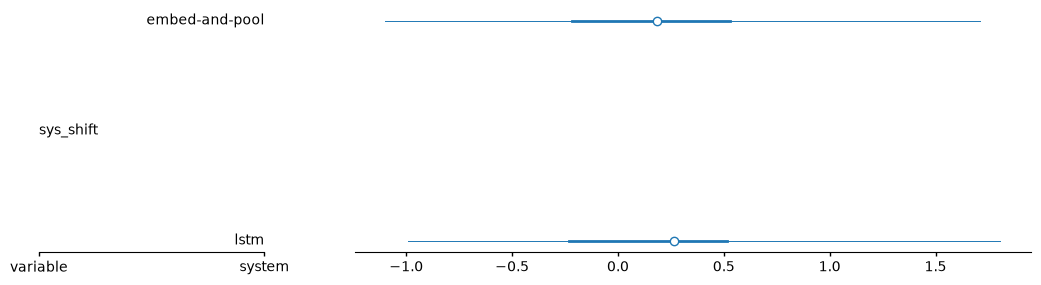

In [86]:
az.plot_forest(
    posterior_data, 
    var_names=['sys_shift'],    
    combined=True,           # Combine chains
    **az_stats_params
)

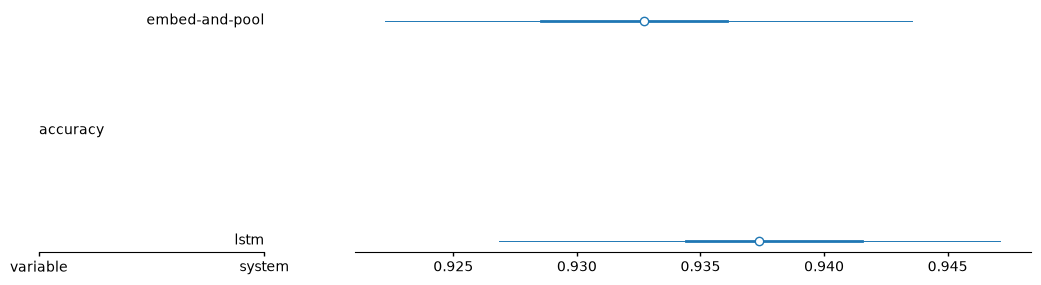

In [87]:
az.plot_forest(
    posterior_data, 
    var_names=['accuracy'],    
    combined=True,           # Combine chains
    **az_stats_params
)

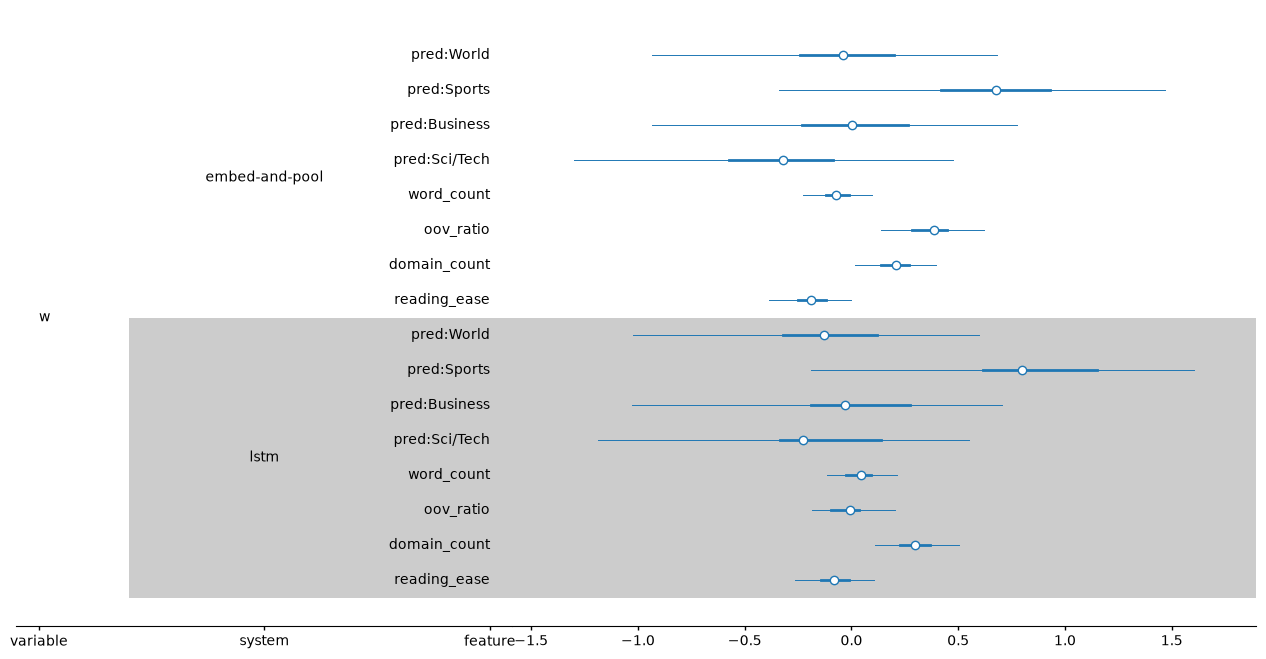

In [ ]:
az.plot_forest(
    posterior_data, 
    var_names=['w'],    
    combined=True,           # Combine chains    
    shade_label="system",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],  # Label panel : interval panel
        "layout": "none",
    },
    **az_stats_params,
)